In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import streamlit as st
import sklearn



In [4]:
file_path = "C:\\Users\\nukan\\Downloads\\AI_INSIGHT_GENERATOR\\data\\sample_-_superstore.xls"
orders = pd.read_excel(file_path, sheet_name="Orders")
returns = pd.read_excel(file_path, sheet_name="Returns")
people = pd.read_excel(file_path, sheet_name="People")


C:\Users\nukan\AppData\Local\Temp\ipykernel_30308\3628022553.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  orders = pd.read_excel(file_path, sheet_name="Orders")
C:\Users\nukan\AppData\Local\Temp\ipykernel_30308\3628022553.py:3: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  returns = pd.read_excel(file_path, sheet_name="Returns")
C:\Users\nukan\AppData\Local\Temp\ipykernel_30308\3628022553.py:4: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  people = pd.read_excel(file_path, sheet_name="People")


In [5]:
orders.shape

(10194, 21)

In [6]:
returns.shape

(296, 2)

In [7]:
people.shape

(4, 2)

In [8]:
orders.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [9]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [10]:
orders.duplicated().sum()

np.int64(0)

In [11]:
orders.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [12]:
orders.describe()

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002943,2025-05-03 10:52:45.626839,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


In [13]:
print("Categories:")
print(orders["Category"].value_counts())

print("\nCustomer Segments:")
print(orders["Segment"].value_counts())

print("\nRegions:")
print(orders["Region"].value_counts())

Categories:
Category
Office Supplies    6128
Furniture          2201
Technology         1865
Name: count, dtype: int64

Customer Segments:
Segment
Consumer       5281
Corporate      3090
Home Office    1823
Name: count, dtype: int64

Regions:
Region
West       3253
East       2986
Central    2335
South      1620
Name: count, dtype: int64


In [14]:
print("Minimum Order Date:", orders["Order Date"].min())
print("Maximum Order Date:", orders["Order Date"].max())

Minimum Order Date: 2023-01-03 00:00:00
Maximum Order Date: 2026-12-30 00:00:00


In [15]:
# Check future dates
future_orders = orders[orders["Order Date"] > pd.Timestamp.today()]

print("\nFuture-dated records:", len(future_orders))

# Check negative sales and profit
print("\nNegative sales:", (orders["Sales"] < 0).sum())
print("Negative profit:", (orders["Profit"] < 0).sum())

# Numerical summary
orders[["Sales", "Quantity", "Discount", "Profit"]].describe()


Future-dated records: 691

Negative sales: 0
Negative profit: 1901


,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,0.155385,28.673417
std,619.906839,2.228317,0.206249,232.465115
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.220000,2.000000,0.000000,1.760800
50%,53.910000,3.000000,0.200000,8.690000
75%,209.500000,5.000000,0.200000,29.297925
max,22638.480000,14.000000,0.800000,8399.976000


In [16]:
# Select loss-making transactions
loss_data = orders[orders["Profit"] < 0]

print("Loss-making records:", len(loss_data))

print("\nLoss by category:")
print(
    loss_data.groupby("Category")["Profit"]
    .sum()
    .sort_values()
)

print("\nLoss by region:")
print(
    loss_data.groupby("Region")["Profit"]
    .sum()
    .sort_values()
)

print("\nLoss by discount:")
print(
    loss_data.groupby("Discount")["Profit"]
    .agg(["count", "sum"])
    .sort_values("sum")
)

Loss-making records: 1901

Loss by category:
Category
Furniture         -61675.1837
Office Supplies   -56783.8283
Technology        -38579.9182
Name: Profit, dtype: float64

Loss by region:
Region
Central   -56371.1035
East      -50187.8375
South     -27504.8323
West      -22975.1569
Name: Profit, dtype: float64

Loss by discount:
          count         sum
Discount                   
0.70        424 -40300.5727
0.80        301 -30565.2692
0.40        181 -25817.1506
0.50         66 -20506.4281
0.20        510 -17521.0801
0.30        211 -10921.8561
0.60        149  -6164.3472
0.45         11  -2493.1111
0.32         27  -2391.1377
0.15         17   -328.7030
0.10          4    -29.2744


In [17]:
discount_analysis = (
    orders.groupby("Discount")
    .agg(
        Total_Records=("Profit", "size"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean"),
        Loss_Records=("Profit", lambda x: (x < 0).sum())
    )
)

discount_analysis["Loss_Percentage"] = (
    discount_analysis["Loss_Records"]
    / discount_analysis["Total_Records"] * 100
)

discount_analysis = discount_analysis.sort_values(
    "Discount", ascending=False
)

discount_analysis.round(2)

,Total_Records,Total_Sales,Total_Profit,Average_Profit,Loss_Records,Loss_Percentage
Discount,,,,,,
0.80,301,16980.15,-30565.27,-101.55,301,100.00
0.70,424,40805.27,-40300.57,-95.05,424,100.00
0.60,149,7105.94,-6164.35,-41.37,149,100.00
0.50,66,58918.54,-20506.43,-310.70,66,100.00
0.45,11,5484.97,-2493.11,-226.65,11,100.00
0.40,207,116497.76,-23086.37,-111.53,181,87.44
0.32,27,14493.46,-2391.14,-88.56,27,100.00
0.30,230,104474.07,-10513.45,-45.71,211,91.74
0.20,3706,773939.40,91079.95,24.58,510,13.76


In [18]:
# Overall business KPIs

total_sales = orders["Sales"].sum()
total_profit = orders["Profit"].sum()
total_orders = orders["Order ID"].nunique()
total_customers = orders["Customer ID"].nunique()
total_quantity = orders["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100

average_order_value = total_sales / total_orders

kpi_summary = {
    "Total Sales": round(total_sales, 2),
    "Total Profit": round(total_profit, 2),
    "Total Orders": int(total_orders),
    "Total Customers": int(total_customers),
    "Total Quantity Sold": int(total_quantity),
    "Profit Margin (%)": round(profit_margin, 2),
    "Average Order Value": round(average_order_value, 2)
}

kpi_summary

{'Total Sales': np.float64(2326534.35),
 'Total Profit': np.float64(292296.81),
 'Total Orders': 5111,
 'Total Customers': 804,
 'Total Quantity Sold': 38654,
 'Profit Margin (%)': np.float64(12.56),
 'Average Order Value': np.float64(455.2)}

In [19]:
category_analysis = (
    orders.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"] * 100
)

category_analysis = category_analysis.sort_values(
    "Total_Sales", ascending=False
)

category_analysis.round(2)

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin
Category,,,,,
Technology,839893.28,146543.38,7017,1560,17.45
Furniture,754747.76,19730.00,8369,1819,2.61
Office Supplies,731893.31,126023.44,23268,3812,17.22


In [20]:
subcategory_analysis = (
    orders.groupby(["Category", "Sub-Category"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"] * 100
)

subcategory_analysis = subcategory_analysis.sort_values(
    "Total_Profit"
)

subcategory_analysis.round(2)


Total_Sales  Total_Profit  Total_Quantity  \
Category        Sub-Category                                              
Furniture       Tables          208020.18     -17753.21            1261   
                Bookcases       115361.20      -3632.07             878   
Office Supplies Supplies         46725.50      -1171.39             653   
                Fasteners         8532.24       2428.64             980   
Technology      Machines        189925.03       3461.98             442   
Office Supplies Labels           12695.04       5572.78            1410   
                Art              27659.01       6653.20            3092   
                Envelopes        16528.36       6988.02             914   
Furniture       Furnishings      95598.13      13891.74            3799   
Office Supplies Appliances      108213.18      18329.48            1750   
                Storage         224644.55      21285.11            3191   
Furniture       Chairs          335768.25      27223.53            2431   
Office Supplies Binders         207354.88      31426.10            6071   
                Paper            79540.54      34511.51            5207   
Technology      Accessories     167380.32      41936.64            2976   
                Phones          331842.64      45050.83            3357   
                Copiers         150745.29      56093.94             242   

                              Total_Orders  Profit_Margin  
Category        Sub-Category                               
Furniture       Tables                 314          -8.53  
                Bookcases              228          -3.15  
Office Supplies Supplies               189          -2.51  
                Fasteners              226          28.46  
Technology      Machines               114           1.82  
Office Supplies Labels                 348          43.90  
                Art                    756          24.05  
                Envelopes              251          42.28  
Furniture       Furnishings            919          14.53  
Office Supplies Appliances             459          16.94  
                Storage                787           9.48  
Furniture       Chairs                 591           8.11  
Office Supplies Binders               1339          15.16  
                Paper                 1205          43.39  
Technology      Accessories            718          25.05  
                Phones                 826          13.58  
                Copiers                 70          37.21

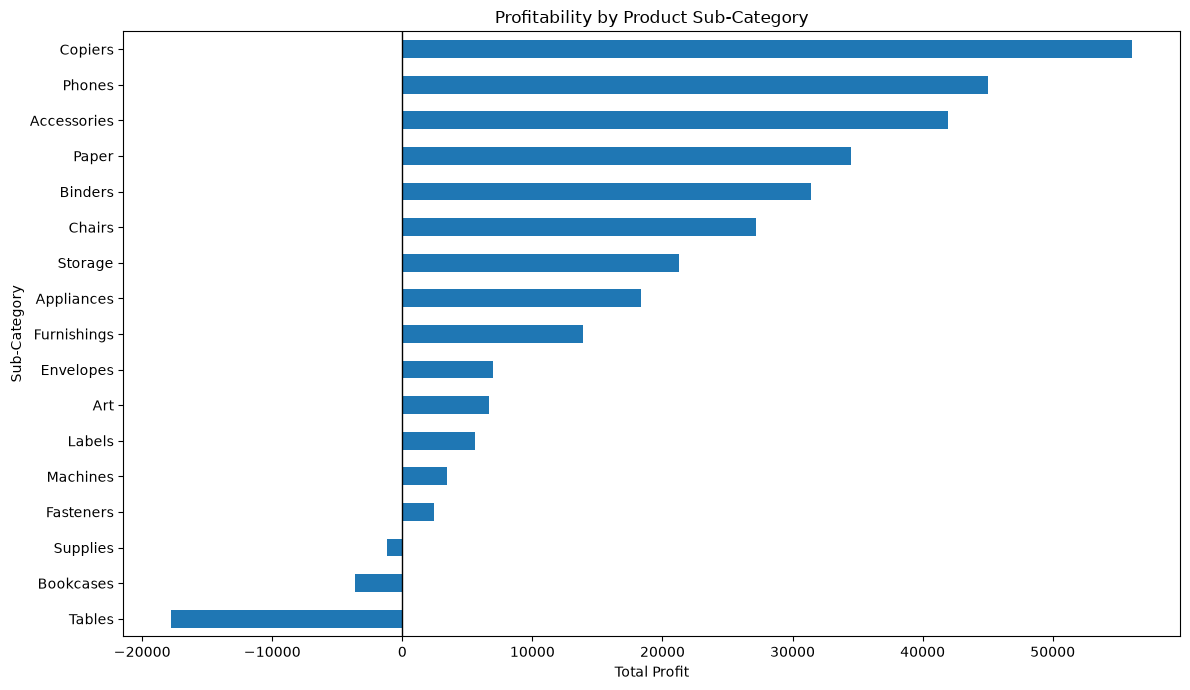

In [21]:
import matplotlib.pyplot as plt

subcategory_profit = (
    orders.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(12, 7))

subcategory_profit.plot(kind="barh")

plt.axvline(x=0, color="black", linewidth=1)

plt.title("Profitability by Product Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("Sub-Category")

plt.tight_layout()
plt.show()

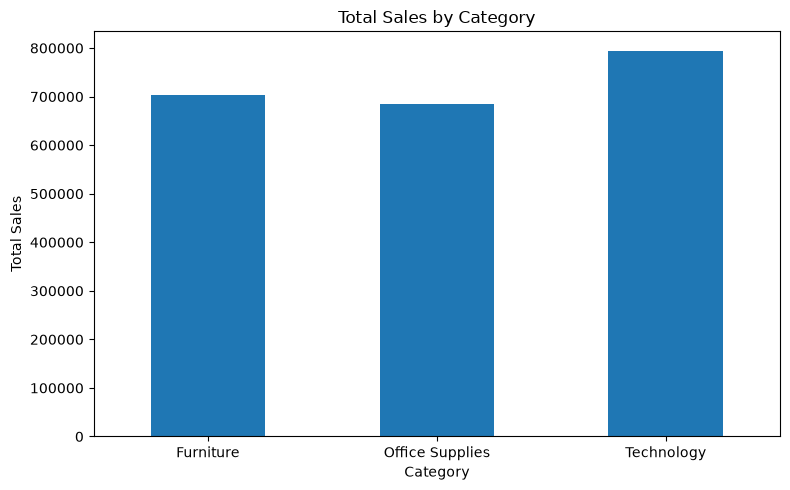

In [64]:
category_sales = orders_clean.groupby("Category")["Sales"].sum()

plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
# Extract year and month
orders["Year_Month"] = orders["Order Date"].dt.to_period("M")

# Calculate monthly performance
monthly_analysis = (
    orders.groupby("Year_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

monthly_analysis.head(15)

,Total_Sales,Total_Profit,Total_Orders
Year_Month,,,
2023-01,14518.0550,2539.3907,33
2023-02,4519.8920,862.3084,28
2023-03,56933.9090,693.4499,72
2023-04,28295.3450,3488.8352,66
2023-05,26319.7670,3196.3918,72
2023-06,34669.4796,4999.7594,67
2023-07,33946.3930,-841.4826,65
2023-08,28918.3385,5765.2250,75
2023-09,82670.4288,8593.6302,134


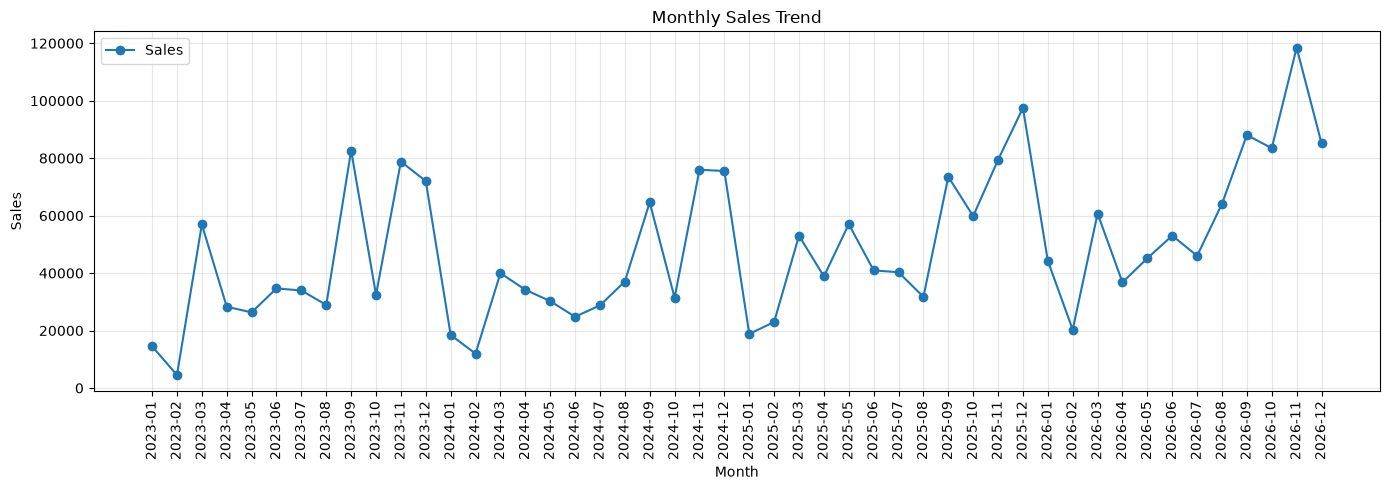

In [23]:
monthly_plot = monthly_analysis.copy()
monthly_plot.index = monthly_plot.index.astype(str)

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_plot.index,
    monthly_plot["Total_Sales"],
    marker="o",
    label="Sales"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=90)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
# Identify future-dated transactions
future_orders = orders[
    orders["Order Date"] > pd.Timestamp.today().normalize()
]

print("Future records:", len(future_orders))

# Inspect their dates
print("\nFuture date distribution:")
print(future_orders["Order Date"].dt.to_period("M").value_counts().sort_index())

# Inspect sample records
future_orders[
    ["Order ID", "Order Date", "Sales", "Profit"]
].head(10)

Future records: 691

Future date distribution:
Order Date
2026-11    209
2026-12    482
Freq: M, Name: count, dtype: int64


,Order ID,Order Date,Sales,Profit
9503,US-2026-124674,2026-11-17,327.7328,-14.4588
9504,US-2026-155866,2026-11-17,187.7600,76.9816
9505,US-2026-165687,2026-11-17,35.0400,12.2640
9506,US-2026-138163,2026-11-17,50.9400,14.2632
9507,US-2026-116505,2026-11-17,43.8000,20.5860
9508,US-2026-118122,2026-11-17,13.9040,4.5188
9509,US-2026-158120,2026-11-17,4.1580,-3.4650
9510,US-2026-100902,2026-11-17,268.2400,93.8840
9511,US-2026-158120,2026-11-17,19.6080,6.6177
9512,US-2026-155866,2026-11-17,38.8800,18.6624


In [25]:
# Define analysis cutoff date
as_of_date = pd.Timestamp.today().normalize()

# Create historical analysis dataset
orders_clean = orders[
    orders["Order Date"] <= as_of_date
].copy()

print("Original records:", len(orders))
print("Future-dated records:", len(orders) - len(orders_clean))
print("Validated records:", len(orders_clean))

print("Date range:")
print(orders_clean["Order Date"].min())
print(orders_clean["Order Date"].max())

Original records: 10194
Future-dated records: 691
Validated records: 9503
Date range:
2023-01-03 00:00:00
2026-11-16 00:00:00


In [26]:
monthly_analysis = (
    orders_clean
    .assign(Year_Month=lambda x: x["Order Date"].dt.to_period("M"))
    .groupby("Year_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

monthly_analysis.tail()

,Total_Sales,Total_Profit,Total_Orders
Year_Month,,,
2026-07,45989.4960,7006.5012,112
2026-08,64129.7580,9488.0722,114
2026-09,88064.5320,11050.8024,231
2026-10,83474.7832,10670.5312,151
2026-11,60136.9772,911.4027,146


In [27]:
monthly_analysis["Profit_Margin"] = (
    monthly_analysis["Total_Profit"]
    / monthly_analysis["Total_Sales"]
) * 100

monthly_analysis["Average_Order_Value"] = (
    monthly_analysis["Total_Sales"]
    / monthly_analysis["Total_Orders"]
)

monthly_analysis.round(2)

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin,Average_Order_Value
Year_Month,,,,,
2023-01,14518.06,2539.39,33,17.49,439.94
2023-02,4519.89,862.31,28,19.08,161.42
2023-03,56933.91,693.45,72,1.22,790.75
2023-04,28295.34,3488.84,66,12.33,428.72
2023-05,26319.77,3196.39,72,12.14,365.55
2023-06,34669.48,4999.76,67,14.42,517.45
2023-07,33946.39,-841.48,65,-2.48,522.25
2023-08,28918.34,5765.22,75,19.94,385.58
2023-09,82670.43,8593.63,134,10.40,616.94


In [28]:
# Find highest and lowest profit months
print("Highest profit month:")
print(monthly_analysis["Total_Profit"].idxmax())

print("\nLowest profit month:")
print(monthly_analysis["Total_Profit"].idxmin())

print("\nHighest sales month:")
print(monthly_analysis["Total_Sales"].idxmax())

Highest profit month:
2025-12

Lowest profit month:
2024-01

Highest sales month:
2025-12


In [29]:
region_analysis = (
    orders_clean.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
)

region_analysis["Profit_Margin"] = (
    region_analysis["Total_Profit"]
    / region_analysis["Total_Sales"]
) * 100

region_analysis = region_analysis.sort_values(
    "Total_Sales", ascending=False
)

region_analysis.round(2)

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
Region,,,,,
West,704431.32,105768.22,1537,11647,15.01
East,638556.57,83226.52,1364,10301,13.03
Central,472842.13,42294.51,1094,8240,8.94
South,367211.78,43571.04,764,5782,11.87


In [30]:
segment_analysis = (
    orders_clean.groupby("Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum"),
        Total_Customers=("Customer ID", "nunique")
    )
)

segment_analysis["Profit_Margin"] = (
    segment_analysis["Total_Profit"]
    / segment_analysis["Total_Sales"]
) * 100

segment_analysis = segment_analysis.sort_values(
    "Total_Sales", ascending=False
)

segment_analysis.round(2)

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Total_Customers,Profit_Margin
Segment,,,,,,
Consumer,1089057.12,126503.34,2429,18321,416,11.62
Corporate,681564.46,91800.21,1450,11135,239,13.47
Home Office,412420.21,56556.74,880,6514,149,13.71


In [31]:
customer_analysis = (
    orders_clean.groupby("Customer ID")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Quantity=("Quantity", "sum")
    )
)

customer_analysis["Profit_Margin"] = (
    customer_analysis["Total_Profit"]
    / customer_analysis["Total_Sales"]
) * 100

top_10_customers = customer_analysis.sort_values(
    "Total_Sales", ascending=False
).head(10)

top_10_customers.round(2)

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
Customer ID,,,,,
SM-20320,25043.05,-1980.74,5,50,-7.91
TC-20980,19052.22,8981.32,5,42,47.14
RB-19360,15117.34,6976.10,6,71,46.15
TA-21385,14595.62,4703.79,4,36,32.23
KL-16645,14175.23,806.85,12,113,5.69
SC-20095,14142.33,5757.41,9,87,40.71
AB-10105,13629.73,5220.36,9,65,38.30
SE-20110,12085.08,2617.10,10,76,21.66
CC-12370,11902.43,2081.41,4,24,17.49


In [32]:
# Bottom 10 customers by total profit

bottom_10_customers = (
    customer_analysis
    .sort_values("Total_Profit")
    .head(10)
)

bottom_10_customers.round(2)

,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin
Customer ID,,,,,
CS-12505,5690.06,-6626.39,6,40,-116.46
GT-14635,9351.21,-4108.66,3,26,-43.94
LF-17185,3711.70,-3636.94,6,55,-97.99
SR-20425,3091.52,-3369.40,4,32,-108.99
SB-20290,8057.89,-2082.75,7,84,-25.85
SM-20320,25043.05,-1980.74,5,50,-7.91
CP-12340,5888.28,-1850.30,8,59,-31.42
NF-18385,8322.83,-1695.97,7,52,-20.38
BM-11140,11789.63,-1659.96,4,64,-14.08


In [33]:
# Overall business KPIs

total_sales = orders_clean["Sales"].sum()
total_profit = orders_clean["Profit"].sum()
total_orders = orders_clean["Order ID"].nunique()
total_customers = orders_clean["Customer ID"].nunique()
total_quantity = orders_clean["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100

average_order_value = total_sales / total_orders

kpi_summary = {
    "Total Sales": round(total_sales, 2),
    "Total Profit": round(total_profit, 2),
    "Total Orders": total_orders,
    "Total Customers": total_customers,
    "Total Quantity": total_quantity,
    "Profit Margin": round(profit_margin, 2),
    "Average Order Value": round(average_order_value, 2)
}

kpi_summary

{'Total Sales': np.float64(2183041.79),
 'Total Profit': np.float64(274860.29),
 'Total Orders': 4759,
 'Total Customers': 804,
 'Total Quantity': np.int64(35970),
 'Profit Margin': np.float64(12.59),
 'Average Order Value': np.float64(458.72)}

In [34]:
kpi_summary = {
    "Total Sales": float(round(total_sales, 2)),
    "Total Profit": float(round(total_profit, 2)),
    "Total Orders": int(total_orders),
    "Total Customers": int(total_customers),
    "Total Quantity": int(total_quantity),
    "Profit Margin": float(round(profit_margin, 2)),
    "Average Order Value": float(round(average_order_value, 2))
}

print(kpi_summary)

{'Total Sales': 2183041.79, 'Total Profit': 274860.29, 'Total Orders': 4759, 'Total Customers': 804, 'Total Quantity': 35970, 'Profit Margin': 12.59, 'Average Order Value': 458.72}


In [45]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

sys.path.insert(0, str(project_root / "src"))

import business_insights as bi
import business_recommendations as br
import data_processor as dp
import main

print("All modules imported successfully!")

All modules imported successfully!


In [47]:
# Calculate category performance

category_analysis = (
    orders_clean.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
) * 100

category_analysis.round(2)

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
Category,,,,
Furniture,703297.99,18570.92,1680,2.64
Office Supplies,685044.46,123260.66,3554,17.99
Technology,794699.34,133028.71,1464,16.74


In [48]:
# Identify the category with the lowest profit margin

lowest_margin_category = category_analysis[
    "Profit_Margin"
].idxmin()

lowest_margin = category_analysis.loc[
    lowest_margin_category, "Profit_Margin"
]

print("Lowest profit margin category:", lowest_margin_category)
print("Profit margin:", round(lowest_margin, 2), "%")

Lowest profit margin category: Furniture
Profit margin: 2.64 %


In [49]:
import sys
from pathlib import Path

# Get the project root folder
project_root = Path.cwd().parent.parent

# Add project root to Python path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Add src folder to Python path
src_path = project_root / "src"

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

print("Project root:", project_root)
print("Project path configured successfully!")

Project root: c:\Users\nukan\Downloads
Project path configured successfully!


In [50]:
subcategory_analysis = (
    orders_clean.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
)

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
) * 100

subcategory_analysis = subcategory_analysis.sort_values(
    "Profit_Margin"
)

subcategory_analysis.round(2)

,Total_Sales,Total_Profit,Total_Orders,Profit_Margin
Sub-Category,,,,
Tables,193495.20,-15555.26,292,-8.04
Supplies,44118.93,-1292.09,177,-2.93
Bookcases,109790.42,-3098.41,211,-2.82
Machines,187636.07,3397.77,110,1.81
Chairs,313377.12,24552.81,550,7.83
Storage,208858.87,19032.05,732,9.11
Phones,313135.97,41149.58,775,13.14
Furnishings,86635.25,12671.77,843,14.63
Appliances,97645.64,17018.46,425,17.43


In [51]:
import importlib
import src.business_insights as bi

importlib.reload(bi)

business_insights = bi.generate_business_insights(
    kpi_summary,
    category_analysis,
    subcategory_analysis
)

for i, insight in enumerate(business_insights, start=1):
    print(f"{i}. {insight}")

1. The business generated total sales of $2,183,041.79.
2. The total profit generated was $274,860.29.
3. The overall profit margin is 12.59%.
4. The business has a profit margin above 10%.
5. The business served 804 unique customers.
6. A total of 4759 unique orders were placed.
7. Furniture has the lowest profit margin at 2.64%.
8. Office Supplies has the highest profit margin at 17.99%.
9. Tables has the lowest profit margin at -8.04%.
10. Labels has the highest profit margin at 43.80%.
11. The following subcategories are generating losses: Tables, Supplies, Bookcases.


In [52]:
import src.business_recommendations as br

recommendations = br.generate_business_recommendations(
    category_analysis,
    subcategory_analysis
)

for i, recommendation in enumerate(recommendations, start=1):
    print(f"{i}. {recommendation}")

1. Review the pricing and discount strategy for Furniture. Its profit margin is only 2.64%. Investigate product costs and discount levels.
2. Investigate Tables, which generated a loss of $15,555.26. Review its pricing, costs and discount patterns.
3. Investigate Supplies, which generated a loss of $1,292.09. Review its pricing, costs and discount patterns.
4. Investigate Bookcases, which generated a loss of $3,098.41. Review its pricing, costs and discount patterns.
5. Study the business strategy behind Labels, which has the highest subcategory profit margin of 43.80%.


In [53]:
import importlib
import src.business_insights as bi

importlib.reload(bi)

business_insights = bi.generate_business_insights(
    kpi_summary,
    category_analysis,
    subcategory_analysis
)

for i, insight in enumerate(business_insights, start=1):
    print(f"{i}. {insight}")

1. The business generated total sales of $2,183,041.79.
2. The total profit generated was $274,860.29.
3. The overall profit margin is 12.59%.
4. The business has a profit margin above 10%.
5. The business served 804 unique customers.
6. A total of 4759 unique orders were placed.
7. Furniture has the lowest profit margin at 2.64%.
8. Office Supplies has the highest profit margin at 17.99%.
9. Tables has the lowest profit margin at -8.04%.
10. Labels has the highest profit margin at 43.80%.
11. The following subcategories are generating losses: Tables, Supplies, Bookcases.


In [54]:
import importlib
import src.business_recommendations as br

importlib.reload(br)

recommendations = br.generate_business_recommendations(
    category_analysis,
    subcategory_analysis
)

for i, recommendation in enumerate(recommendations, start=1):
    print(f"{i}. {recommendation}")

1. Review the pricing and discount strategy for Furniture. Its profit margin is only 2.64%. Investigate product costs and discount levels.
2. Investigate Tables, which generated a loss of $15,555.26. Review its pricing, costs and discount patterns.
3. Investigate Supplies, which generated a loss of $1,292.09. Review its pricing, costs and discount patterns.
4. Investigate Bookcases, which generated a loss of $3,098.41. Review its pricing, costs and discount patterns.
5. Study the business strategy behind Labels, which has the highest subcategory profit margin of 43.80%.


In [57]:
from pathlib import Path

project_root = Path.cwd().parent

file_path = project_root / "data" / "sample_-_superstore.xls"

print("File exists:", file_path.exists())
print("File path:", file_path)

File exists: True
File path: c:\Users\nukan\Downloads\AI_INSIGHT_GENERATOR\data\sample_-_superstore.xls


In [ ]:
from pathlib import Path

project_root = Path.cwd().parent.parent

print("Project folder:", project_root)

print("\nExcel files found inside project:")

for file in project_root.rglob("*.xls*"):
    print(file)

Project folder: c:\Users\nukan\Downloads\AI_INSIGHT_GENERATOR

Excel files found inside project:
c:\Users\nukan\Downloads\AI_INSIGHT_GENERATOR\data\sample_-_superstore.xls


In [58]:
analysis_results = main.run_business_analysis(file_path)

Excel file loaded successfully!
Dataset shape: (10194, 21)
Data cleaning completed!
Cleaned dataset shape: (9503, 21)

========== BUSINESS KPIs ==========

Total Sales: 2183041.79
Total Profit: 274860.29
Total Orders: 4759
Total Customers: 804
Total Quantity: 35970
Profit Margin: 12.59
Average Order Value: 458.72

========== BUSINESS INSIGHTS ==========

1. The business generated total sales of $2,183,041.79.
2. The total profit generated was $274,860.29.
3. The overall profit margin is 12.59%.
4. The business has a profit margin above 10%.
5. The business served 804 unique customers.
6. A total of 4759 unique orders were placed.
7. Furniture has the lowest profit margin at 2.64%.
8. Office Supplies has the highest profit margin at 17.99%.
9. Tables has the lowest profit margin at -8.04%.
10. Labels has the highest profit margin at 43.80%.
11. The following subcategories are generating losses: Bookcases, Supplies, Tables.

========== BUSINESS RECOMMENDATIONS ==========

1. Review the p

In [4]:
import importlib
import ai_generator

importlib.reload(ai_generator)

ai_report = ai_generator.generate_ai_business_report(prompt)

print(ai_report)

RateLimitError: Error code: 429 - You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.